### Step-1: Importing Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

### Step-2: Loading the Iris Dataset

In [2]:
df = pd.read_csv("iris.csv")
print("First 5 Rows:")
print(df.head())

First 5 Rows:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


### Step-3: Exploring the Dataset

In [3]:
print("Dataset Shape:", df.shape)
print("\nDataset Information:")
df.info()
print("\nStatistical Summary:")
print(df.describe())

Dataset Shape: (150, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Statistical Summary:
       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.054000      3.758667     1.198667
std        0.828066     0.433594      1.764420     0.763161
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.400000     3.300000      5.100000     1.80

### Step-4: Checking Column Names

In [4]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']


### Step-5: Checking Missing Values

In [5]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


### Step-6: Checking Duplicate Records

In [6]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 3


### Step-7: Visualizing the Dataset

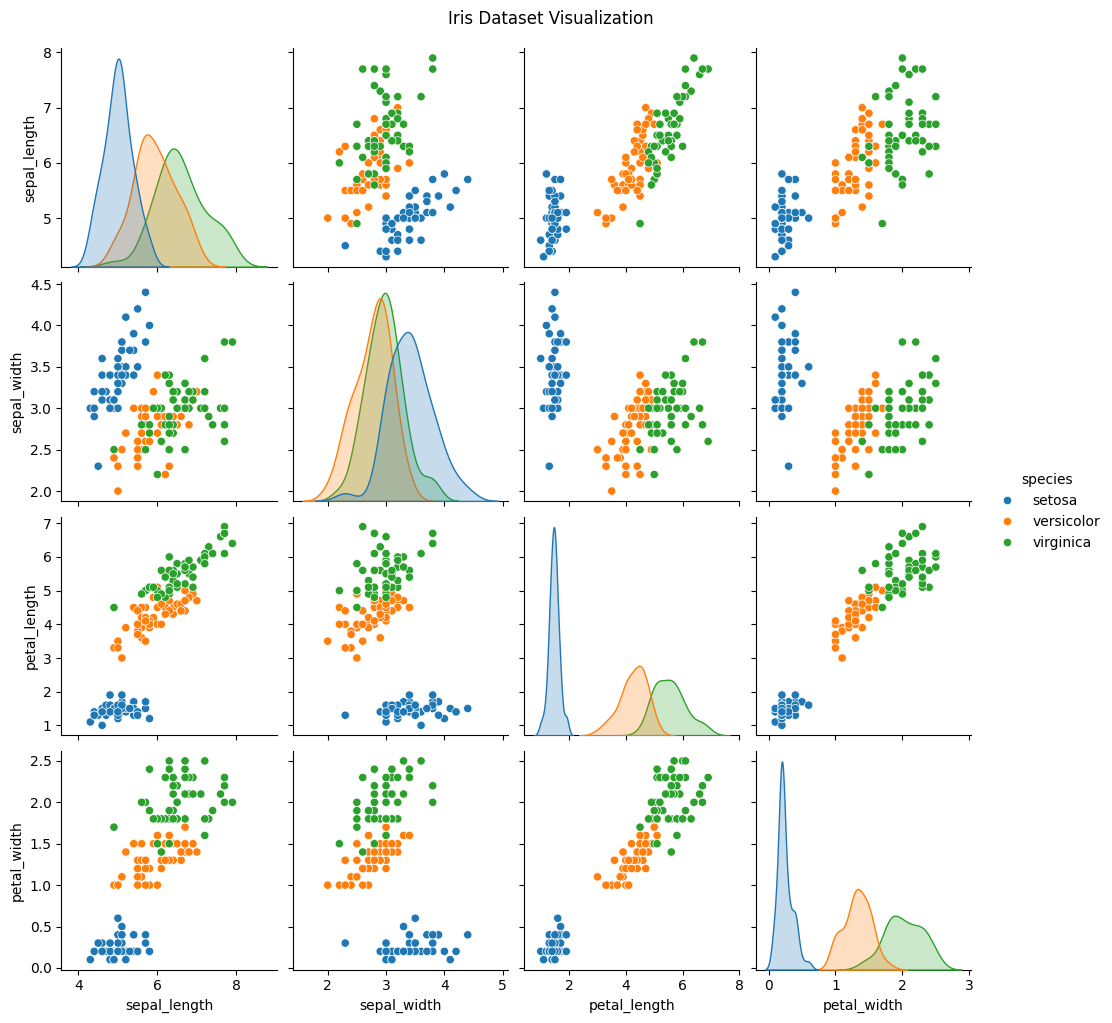

In [7]:
sns.pairplot(df, hue='species')
plt.suptitle("Iris Dataset Visualization", y=1.02)
plt.show()

### Step-8: Separating Features and Target Variable

In [8]:
X = df.drop('species', axis=1)
y = df['species']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (150, 4)
Target Shape: (150,)


### Step-9: Splitting the Dataset into Training and Testing Sets

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (120, 4)
Testing Data: (30, 4)


### Step-10: Building the Decision Tree Classifier

In [10]:
model = DecisionTreeClassifier(random_state=42)
print("Decision Tree Classifier Created Successfully!")

Decision Tree Classifier Created Successfully!


### Step-11: Training the Decision Tree Model

In [11]:
model.fit(X_train, y_train)
print("Model Trained Successfully!")

Model Trained Successfully!


### Step-12: Visualizing the Decision Tree

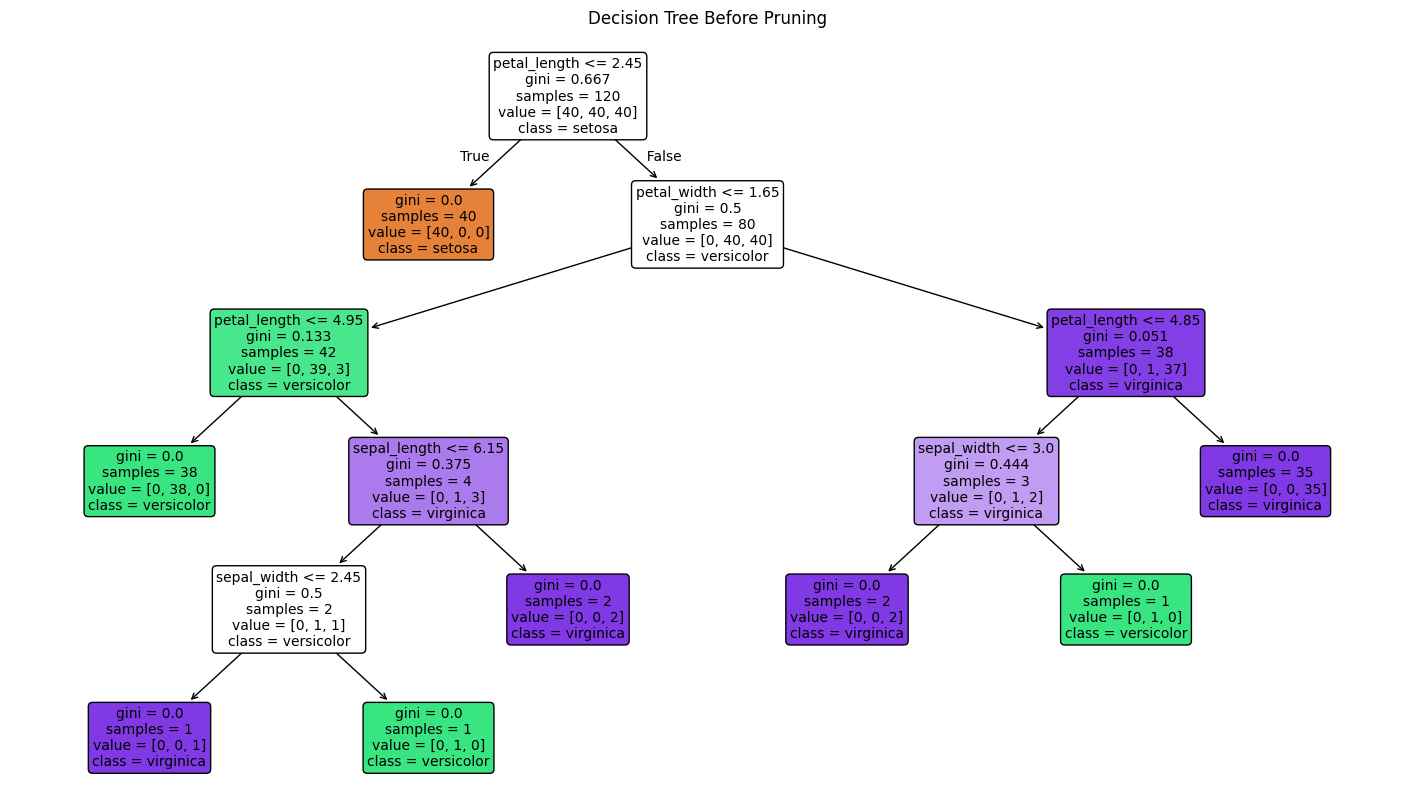

In [12]:
plt.figure(figsize=(18, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree Before Pruning")
plt.show()

### Step-13: Making Predictions

In [13]:
y_pred = model.predict(X_test)

print("Actual Values:")
print(y_test.tolist())

print("\nPredicted Values:")
print(y_pred)

Actual Values:
['setosa', 'virginica', 'versicolor', 'versicolor', 'setosa', 'versicolor', 'setosa', 'setosa', 'virginica', 'versicolor', 'virginica', 'virginica', 'virginica', 'versicolor', 'setosa', 'setosa', 'setosa', 'versicolor', 'versicolor', 'virginica', 'setosa', 'virginica', 'versicolor', 'virginica', 'virginica', 'versicolor', 'versicolor', 'setosa', 'virginica', 'setosa']

Predicted Values:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']


### Step-14: Evaluating the Model Before Pruning

In [14]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.9333333333333333
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1 Score: 0.9333333333333333


### Step-15: Generating the Classification Report 

In [15]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



### Step-16: Visualizing the Confusion Matrix

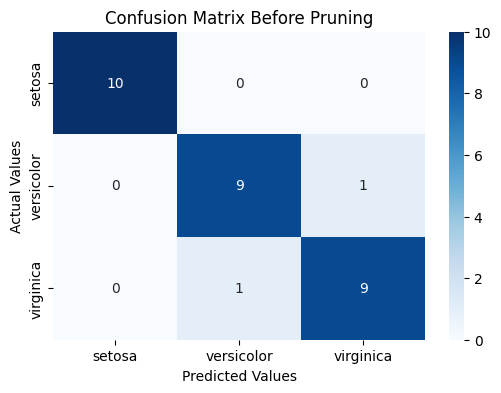

In [16]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Confusion Matrix Before Pruning")
plt.show()

### Step-17: Finding the Best Pruning Parameter

In [17]:
path = model.cost_complexity_pruning_path(X_train, y_train)

ccp_alphas = path.ccp_alphas

print("Pruning Parameters:")
print(ccp_alphas)

Pruning Parameters:
[0.         0.00625    0.00811404 0.03392857 0.27067669 0.33333333]


### Step-18: Visualizing the Effect of Pruning

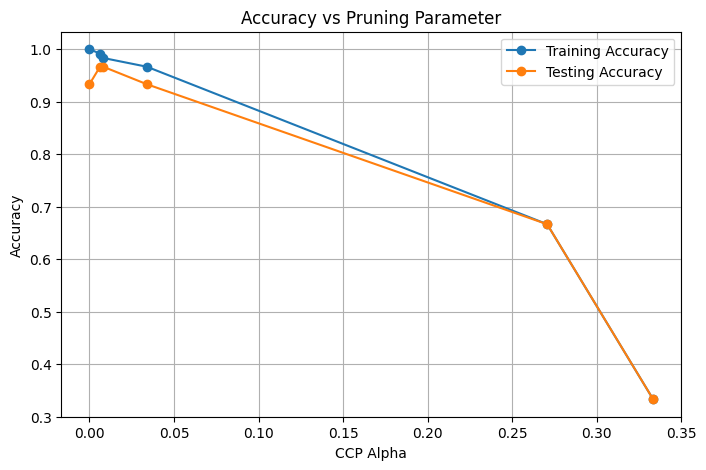

In [18]:
train_scores = []
test_scores = []

for alpha in ccp_alphas:
    clf = DecisionTreeClassifier(
        random_state=42,
        ccp_alpha=alpha
    )

    clf.fit(X_train, y_train)

    train_scores.append(clf.score(X_train, y_train))
    test_scores.append(clf.score(X_test, y_test))

plt.figure(figsize=(8, 5))

plt.plot(ccp_alphas, train_scores, marker='o', label='Training Accuracy')
plt.plot(ccp_alphas, test_scores, marker='o', label='Testing Accuracy')

plt.xlabel("CCP Alpha")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Pruning Parameter")
plt.legend()
plt.grid(True)
plt.show()

### Step-19: Selecting the Best Pruning Parameter

In [19]:
best_alpha = ccp_alphas[np.argmax(test_scores)]
print("Best CCP Alpha:", best_alpha)

Best CCP Alpha: 0.00625


### Step-20: Building the Pruned Decision Tree

In [20]:
pruned_model = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=best_alpha
)

pruned_model.fit(X_train, y_train)

print("Pruned Decision Tree Trained Successfully!")

Pruned Decision Tree Trained Successfully!


### Step-21: Visualizing the Pruned Decision Tree

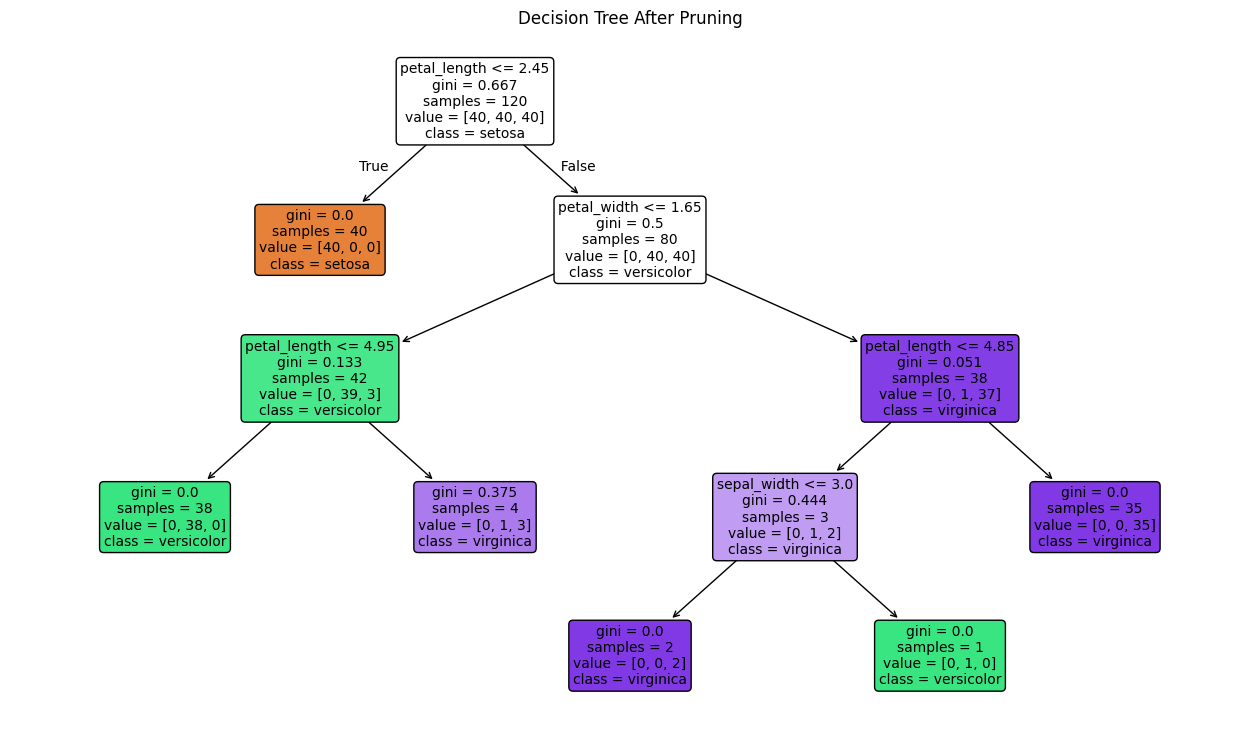

In [21]:
plt.figure(figsize=(16, 9))

plot_tree(
    pruned_model,
    feature_names=X.columns,
    class_names=pruned_model.classes_,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree After Pruning")
plt.show()

### Step-22: Making Predictions Using the Pruned Model

In [22]:
y_pred_pruned = pruned_model.predict(X_test)

print("Actual Values:")
print(y_test.tolist())

print("\nPredicted Values After Pruning:")
print(y_pred_pruned)

Actual Values:
['setosa', 'virginica', 'versicolor', 'versicolor', 'setosa', 'versicolor', 'setosa', 'setosa', 'virginica', 'versicolor', 'virginica', 'virginica', 'virginica', 'versicolor', 'setosa', 'setosa', 'setosa', 'versicolor', 'versicolor', 'virginica', 'setosa', 'virginica', 'versicolor', 'virginica', 'virginica', 'versicolor', 'versicolor', 'setosa', 'virginica', 'setosa']

Predicted Values After Pruning:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'virginica'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']


### Step-23: Evaluating the Pruned Model

In [23]:
accuracy = accuracy_score(y_test, y_pred_pruned)
precision = precision_score(
    y_test, y_pred_pruned, average='weighted'
)
recall = recall_score(
    y_test, y_pred_pruned, average='weighted'
)
f1 = f1_score(
    y_test, y_pred_pruned, average='weighted'
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.9666666666666667
Precision: 0.9696969696969696
Recall: 0.9666666666666667
F1 Score: 0.9665831244778613


### Step-24: Generating the Classification Report After Pruning

In [24]:
print(classification_report(y_test, y_pred_pruned))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



### Step-25: Visualizing the Confusion Matrix After Pruning

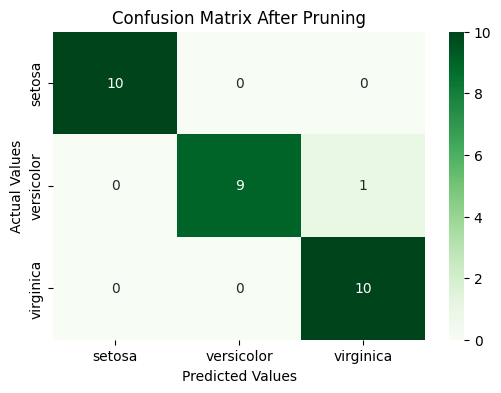

In [25]:
cm = confusion_matrix(y_test, y_pred_pruned)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=pruned_model.classes_,
    yticklabels=pruned_model.classes_
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Confusion Matrix After Pruning")
plt.show()

### Step-26: Comparing Before and After Pruning

In [26]:
before_accuracy = accuracy_score(y_test, y_pred)
after_accuracy = accuracy_score(y_test, y_pred_pruned)

before_f1 = f1_score(y_test, y_pred, average='weighted')
after_f1 = f1_score(y_test, y_pred_pruned, average='weighted')

comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'F1 Score'],
    'Before Pruning': [before_accuracy, before_f1],
    'After Pruning': [after_accuracy, after_f1]
})

print(comparison)

     Metric  Before Pruning  After Pruning
0  Accuracy        0.933333       0.966667
1  F1 Score        0.933333       0.966583


### Step-27: Comparing Tree Complexity

In [27]:
print("Tree Depth Before Pruning:", model.get_depth())
print("Tree Depth After Pruning:", pruned_model.get_depth())

print("Leaves Before Pruning:", model.get_n_leaves())
print("Leaves After Pruning:", pruned_model.get_n_leaves())

Tree Depth Before Pruning: 5
Tree Depth After Pruning: 4
Leaves Before Pruning: 8
Leaves After Pruning: 6
